# Atlas · Evidence pipeline evaluation

Reproducible portfolio analysis. Run all cells from a fresh kernel. Results concern the bundled demonstration data only.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Offline evaluation
The fixed corpus supports reproducible citation-integrity tests without API credits. These checks measure provenance handling, not factual accuracy.

In [2]:
from app.services.workflow import build_graph, verify
import pandas as pd
graph=build_graph()
questions=['How does retrieval augmented generation work?','How can BM25 rank research sources?','How do long contexts affect model reliability?']
rows=[]
for question in questions:
    state=graph.invoke({'topic':question,'mode':'demo','trace':[]})
    rows.append({'topic':question,'accepted':state['verification']['accepted'],'rejected':state['verification']['rejected'],'latency_ms':sum(t['duration_ms'] for t in state['trace'])})
display(pd.DataFrame(rows))

,topic,accepted,rejected,latency_ms
0,How does retrieval augmented generation work?,4,0,2.32
1,How can BM25 rank research sources?,4,0,1.45
2,How do long contexts affect model reliability?,4,0,1.20


Unknown source and fabricated excerpt both rejected


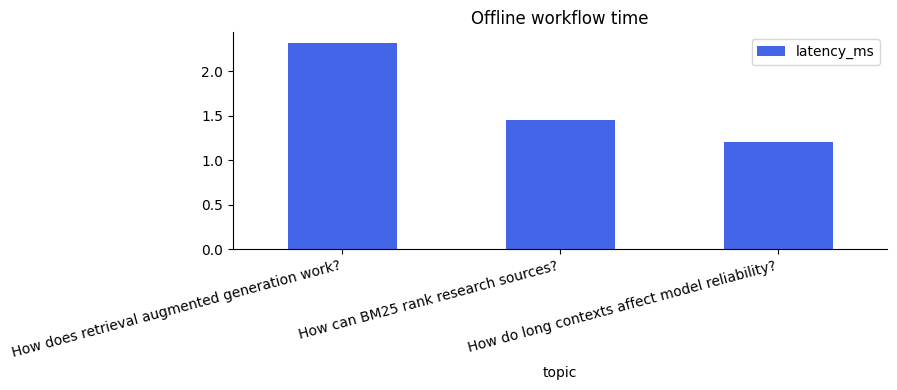

In [3]:
injected={'sources':[{'id':'S1','text':'An authentic source excerpt with enough characters.'}], 'findings':[{'claim':'Unsupported','source_id':'S99','evidence':'Invented evidence which is not in the corpus.'},{'claim':'Another unsupported claim','source_id':'S1','evidence':'Fabricated quote with sufficient length.'}],'trace':[]}
checked=verify(injected)
assert checked['verification']['accepted']==0
assert checked['verification']['rejected']==2
print('Unknown source and fabricated excerpt both rejected')
pd.DataFrame(rows).plot.bar(x='topic',y='latency_ms',color='#4366e9',title='Offline workflow time');plt.xticks(rotation=15,ha='right');plt.tight_layout();plt.show()

## Interpretation
An exact excerpt can still be used to support a misleading claim. Live evaluation needs human-labelled entailment, source authority, freshness, topic coverage and cost-per-supported-finding. Retrieved text is untrusted and cannot invoke tools; no automated actions occur from report content.